# Free Space Quantum Key Distribution Channel

Free Space QKD Channel is a technology that enables secure communication over optical links instead of relying on traditional fibres. 

Recent advancements included the demonstration of a free space data transfer channel that integrates QKD over Li-Fi(Light Fidelity), allowing for quantum secure key delivery in secure environments, for maritime and industrial applications.

## Layer 1: The Physics-

When a satellite sends data to Earth, it encounters the following parameters that reduce the signal:

1. **Geometric/Diffraction Loss**- the laser beam is not perfectly parallel throughout. Especially when it is travelling from an altitude of $500$ km above Earth, by the time it reaches the surface, the beam spot can be a few metres wide whereas our telescopes can be $1$m wide, and thus most of the photons are missed.

The beam radius at a distance say L is given as $w_L = w_0 * \sqrt{1+(\frac{L}{Z_r})^2}$

Here, $w_0$ is the initial beam width, $Z_r = \frac{w_0^2 * \pi}{\lambda}$, is the Rayleigh range with the wavelength at typicalls $\lambda = 850$nm (Near Infrared) for satellite QKD.

The fraction of light collected by a receiver aperture of radius a is: $\eta_{geo} = 1 − exp(−2a²/w_L²)$

2. **Atmospheric Absorption**- the atmosphere also absorbs some photons. At Zenith, transmission rate could be around $80 \%$ with $20 \%$ losses, but at lower elevations, loss increases as $T_{atm} = T_{zenith}^{\frac{1}{sin(elevation)}}$

3. **Receiver Optics**- mirrors, filters, and detector coupling aren't perfect. Typically $\eta_{optics} ≈ 0.5$.
The total channel transmittance is: $\eta_{total} = \eta_{geo} × T_{atm} × \eta_{optics}$ 

In [1]:
#header files

import numpy as np

## First Loss Component- Geometric/Diffraction Loss

In [3]:
#Geometric Efficiency Function

w_0 = float(input("Enter the initial beam width in m:"))
L = float(input("Enter the length of transmission in m:"))
a = float(input("Enter the radius of the receiving telescope dish in m:"))
wlen = float(input("Enter the wavelength of operation in m:"))

def geo_eff(w_0, L, wlen, a):
    Z_r = w_0**2 * np.pi / wlen            #Rayleigh range
    w_l = w_0 * np.sqrt(1+(L/Z_r)**2)      #Beam radius at the transmission length
    eta_geo = 1 - np.exp(-2*a**2 / w_l**2)   #Geometric Efficiency
    return eta_geo

result = geo_eff(w_0, L, wlen, a)
print("For the given parameters, the geometric efficiency is: ", result)

Enter the initial beam width in m: 0.05
Enter the length of transmission in m: 500000
Enter the radius of the receiving telescope dish in m: 0.5
Enter the wavelength of operation in m: 850e-9


For the given parameters, the geometric efficiency is:  0.06599962837869378


As we can see from above, for a distance of $500$km, with a typical receiving telescope of dish diameter $1$m, we have a transmission efficiency of only $6.6\%$, which means about roughly $1$ in every $15$ photons actually enter the telescope. This proves that our beam has actually spread over the entire transmission length.

## Second Loss Component- Atmospheric Absorption

In [5]:
#Atmospheric Transmittance

T_zen = float(input("Please enter the transmission rate at Zenith in decimals (1 being 100% transmittance): "))
elevation = np.radians(float(input("Please enter the elevation angle from the ground (90 being straight up): ")))

def atm_transm(T_zen, elevation):
    T_atm = T_zen**(1/np.sin(elevation))
    return T_atm

transm = atm_transm(T_zen, elevation)

print("The atmospheric transmittance is around:", transm)

Please enter the transmission rate at Zenith in decimals (1 being 100% transmittance):  0.8
Please enter the elevation angle from the ground (90 being straight up):  90


The atmospheric transmittance is around: 0.8


For a lower angle of receiving the signal $20^\circ$, the transmittance is around $52\%$ with a loss of $48\%$, whereas if the elevation is straight up i.e. $90^\circ$, the transmittance is around $80\%$ with $20\%$ loss.

## Total Channel Transmittance- Combining the two loss parameters with receiver optics.

In [7]:
#Total Transmittance

eta_opt = 0.5
def tot_transm(eta_geo, T_atm, eta_opt):
    eta_tot = eta_geo * T_atm * eta_opt
    return eta_tot

total = tot_transm(geo_eff(w_0, L, wlen, a), atm_transm(T_zen, elevation), eta_opt)
loss_db = -10*np.log10(total)
print("The total db Loss is: ", loss_db)

The total db Loss is:  15.783985184867905


## Layer 2: The Detector Model and QBER

When Bob's detector receives photons from the channel, several imperfections affect the measurement:

1. **Detector Efficiency($\eta_{det}$)**- there is no perfect detector. No detector clicks with a $100\%$ efficiency. A typical detector has a detecting efficiency of around $10-30\%$, of registering a photon that actually arrives.
2. **Dark Counts ($Y_0$)**- sometimes our detectors click even when there are no photons. Thermal noise, electric fluctuations or stray light can cause false detections. Typical values range from $Y_0 \approx 10^{-6} - 10^{-5}$ per pulse (very rare, but they matter when the signal is weak).
3. **Misalignment Error ($e_d$)**- even in a perfect channel with no Eve, Bob's measurement apparatus isn't perfectly aligned. Maybe the polarization optics are slightly off. This causes a small baseline error rate, typically $e_d \approx 0.001 - 0.003 (1\% - 3\%)$.

## QBER- Quantum Bit Error Rate

The Quantum Bit Error Rate determines the fraction of qubits which are received incorrectly by a quantum communication system, serving as a key indicator for security and reliability. QBER is calculated as-

The single-photon yield (probability that a pulse caused a click) is:
$Y_1 = Y_0 + \eta_{total} * \eta_{det}$

This combines dark counts with real detections. When channel loss is low, real detections dominate. When loss is high, dark counts dominate.

The **QBER** comes from two error sources:

1. Real photons that get measured due to wrong alignment given by $(e_d)$.
2. Dark Counts that produce random results, say the error rate is around $0.5$.

The combined **QBER** is thus calculated as:

$QBER = (e_d * \eta_{total} * \eta_{det} + 0.5 * Y_0) / Y_1$

In [9]:
#QBER Calculation Function

eta_det = float(input("Please enter the detector efficiency (1 being the highest): "))
Y_0 = float(input("Enter dark count probability (e.g. 1e-6): "))
e_d = float(input("Enter misalignment error (e.g. 0.02): "))

def qber_calc(total, eta_det, Y_0, e_d):
    Y_1 = Y_0 + total*eta_det
    QBER = (e_d * total * eta_det + 0.5 * Y_0) / Y_1
    return QBER

rate = qber_calc(total, eta_det, Y_0, e_d)

print("The QBER calculated for the above scenario is: ", rate)

Please enter the detector efficiency (1 being the highest):  0.2
Enter dark count probability (e.g. 1e-6):  1e-6
Enter misalignment error (e.g. 0.02):  0.02


The QBER calculated for the above scenario is:  0.020090892388222654


In [11]:
rate_lossy = qber_calc(0.0001, 0.2, 1e-6, 0.02)
print("QBER for lossy channel:", rate_lossy)

QBER for lossy channel: 0.04285714285714286


In [13]:
print("QBER at 0.00001:", qber_calc(0.00001, 0.2, 1e-6, 0.02))
print("QBER at 0.000001:", qber_calc(0.000001, 0.2, 1e-6, 0.02))

QBER at 0.00001: 0.18
QBER at 0.000001: 0.42


As we can see for the above three scenarios as, total transmission loss increases for the channel, QBER approaches approximately $50\%$. For channels with fewer losses, where misalignment errors predominate, the QBER is mostly in the range of $2\%$. But as losses become more and more predominant in the channels, the dark counts tend to manipulate the signals and thus the error rate increase even if the dark counts did not increase in all the cases. This is what is important for the real QKD engineers. 

Based on the BB84 protocol, we know that an eavesdropper say Eve induces $25\%$ of errors in the system. And for a lossy channel of $\eta_{tot} = 0.00001$, the channel itself induces an error rate of $18\%$. So, one may ponder, how does the transmitter and receiver distinguish between errors by an eavesdropper and a lossy channel? They do so, by setting a **QBER Threshold** to lets say, $11\%$. If it exceeds this threshold, irrespective of whether because of Eve or channel, they will simply abort, because they cannot clearly distinguish between the error sources. So a noisy channel limits the maximum QKD distance, because for longer distances, the losses increase for the channel and they dominate over all the other error sources and single-handedly exceed the threshold. 

## The Money Plot- QBER vs Channel Loss.

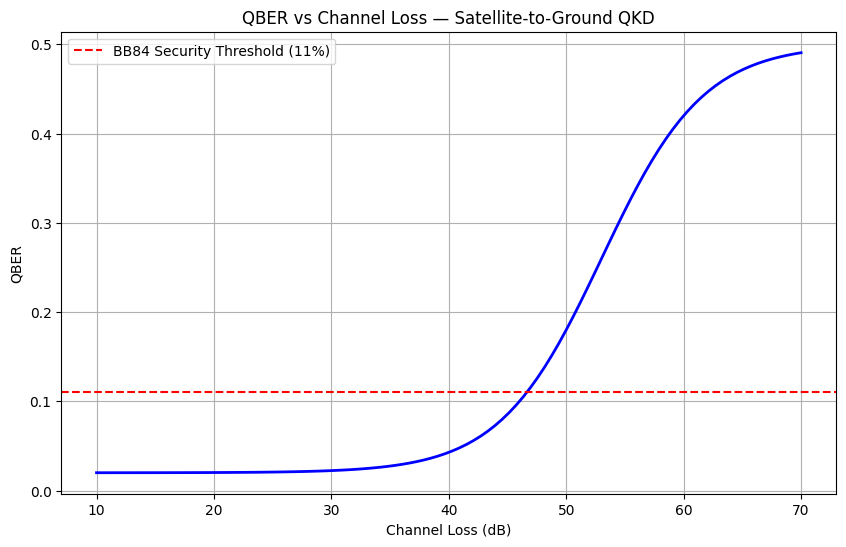

In [15]:
import matplotlib.pyplot as plt

eta_values = np.logspace(-1, -7, 100)  # 0.1 down to 0.0000001

qber_values=[]  
for eta in eta_values:
    qber_values.append(qber_calc(eta, 0.2, 1e-6, 0.02))

dbloss= []
for i in eta_values:
    dbloss.append(-10*np.log10(i))

#Plotting

plt.figure(figsize=(10, 6))
plt.plot(dbloss, qber_values, 'b-', linewidth=2)
plt.axhline(y=0.11, color='r', linestyle='--', label='BB84 Security Threshold (11%)')
plt.xlabel('Channel Loss (dB)')
plt.ylabel('QBER')
plt.title('QBER vs Channel Loss — Satellite-to-Ground QKD')
plt.legend()
plt.grid(True)
plt.show()

From the plot we can see that for channel losses of $10-30$dB, the QBER remains below the threshold as alignment related errors dominate and the signal is strong enough to be manipulated by the dark counts. For channel losses at around $35-45$dB, the QBER starts climbing and it exceeds the threshold of say $11\%$ for our case. From here onwards, especially when it exceeds the threshold, the channel becomes too lossy to neglect the effects of dark counts. 

That crossing point at $~48$ dB is a real physical result. It tells us the maximum distance or minimum elevation angle at which this QKD system can operate. Published satellite QKD papers show similar thresholds in the 40-50 dB range depending on detector quality. Our earlier calculations showed us that the losses reported were around $~15.8$ dB for $90^\circ$ and $~17.6$ dB for $20^\circ$ angles respectively, and so a satellite can easily operate in these ranges at a distance of about $500$ km.

## Layer 3- Decoy-State Secure Key Rate

So far we have covered the physical aspects of the type of errors encountered by a signal through a channel between the transmitter and receiver, and also how the Quantum Bit Error Rate gets affected. Now we shall discuss about the actual communication system starting from the laser used by Alice to transfer her photons to Bob. In theory, such as in BB84, Alice makes use of a single photon source and sends one photon per pulse. But, practically, the lasers are not stable at all and we do not have a perfectly single photon source that will send single photon per pulse. 

Eve can make use of this disadvantage and perform a what is called a **PNS** attack or a Photon Number Splitting Attack, wherein she can split the photons from a pulse comprising of multiple photons. She can keep that photon whilst allowing the remaining photons to pass through. Both Alice and Bob will be unaware because they are unaware of the number of photons generated per pulse. Also, the **No-Cloning Theorem** is also preserved because Alice only stores the extra photon from the multi-photon pulse.

In order to tackle this, Alice sends three types of pulses with different intensities-

1. **Signal Intensity $\mu$**- (e.g. $0.5$ photons per pulse) which is used for the key generation.
2. **Decoy Intensity $\nu$**- (e.g. $0.1$ photons per pulse) used for security estimation.
3. **Vacuum Intensity**- ($\approx 0$ photons per pulse) for measuring dark counts.

Eve is unaware of the intensity choice of these three pulses by Alice. So, everytime she performs a **PNS Attack**, the intensities are manipulated which can be detected by both Alice and Bob.

### Secure Key Rate Formula-

$R = q * \{Q_1 * [1 - H_2(e_1)]-Q_\mu * f * H_2(E_\mu)\}$

with the following parameters-

1. $q$ is the sifting factor, for instance for BB84 it is $0.5$.
2. $Q_1$ is the single photon gain estimated from the decoy states.
3. $e_1$ is the single photon error rate, estimated from the decoy states.
4. $Q_\mu$ is the overall gain at signal intensity.
5. $E_\mu$ is the QBER at signal intensity.
6. $f$ is the error correction efficiency.
7. $H_2$ is the binary entropy function which is given as $H_2 = -x * log_2(x) - (1-x) * log_2(1-x)$, where x is a probability between $0 - 1$.

In [17]:
#Binary Entropy Function

x= float(input("Enter a probability distribution between 0 and 1:" ))

def binary_entropy(x):
    if x==1 or x==0:
        return 0
    elif 0 < x < 1:
        H= -x*np.log2(x) - (1-x)*np.log2(1-x)
        return H
    else:
        print("Enter a valid probability")

bin_ent=binary_entropy(x)

print("The binary entropy function is: ", bin_ent)

Enter a probability distribution between 0 and 1: 0.11


The binary entropy function is:  0.499915958164528


As we can see from above, with a QBER of $11\%$, the entropy error correction consumes almost half of the secret key. That is why the QBER threshold is set at around $11\%$.

### The Gain and The QBER for Weak Coherent Pulses

This is where we consider the fact that Alice is using real lasers which are not generating single photons per pulse. A weak coherent pulse with a mean photon number of $\mu$ follows a Poisson Distribution. So the probability of having $n$ photons in a pulse is given as-

$P(n) = exp(-\mu)*(\mu)^n / n!$

The overall gain (probability that Bob's detectors click) for signal intensity $\mu$ is:

$Q_\mu = Y_0 + 1 - exp(-\eta * \mu)$

Thus, the overall QBER at signal intensity $\mu$ is-

$E_\mu = (e_d * (1 - exp(-\eta * \mu)) + 0.5 * Y_0) / Q_\mu$

In [19]:
#Gain and QBER function

def gain_qber(mu, eta, Y0, e_d):
    Q_mu = Y0 + 1 - np.exp(-eta * mu)
    E_mu = (e_d * (1 - np.exp(-eta * mu)) + 0.5 * Y0) / Q_mu
    return Q_mu, E_mu

Q_mu, E_mu=gain_qber(0.5, 0.026, 1e-6, 0.02)

print("Q_mu:", Q_mu)
print("E_mu:", E_mu)

Q_mu: 0.01291686497971234
E_mu: 0.020037160719784217


## Decoy-State Estimation

As discussed earlier, due to lack of perfect single photon sources, Eve can perform a **PNS Attack** (Photon-Number Splitting) on a multi-photon pulse, keeping photons for herself and allowing the remaining ones from the pulse to pass through. Alice may use a weak coherent laser source but this compromises on the QKD speed. The Decoy-State method was first proposed by Won-Young Hwang from Northwestern University, while the first vacuum+weak decoy state was first proposed by Hoi-Kwong Lo from University of Toronto. For the first single decoy state method, they achieved the transmission distance of nearly $15$ km. Later on, when they implemented the vacuum+weak decoy state, the QKD was demonstrated through a $60$ km long optic fibre.

Alice sends three different signal pulses with different intensities. By comparing the gains at different intensities, one can estimate the single-photon gain $Q_1$ and error rate $e_1$, essential for the security proofs.

The key boundaries of this decoy state method is as follows-

**Single Photon Gain**-

$Q_1 \geq ((\mu)/(\mu\nu - \nu^2))*(Q_\mu × e^\nu − Q_\mu × e^\mu × (\nu^2/\mu^2) − Y_0 × ((\mu^2 − \nu^2)/\mu^2))$

**Single Photon Error Rate**-

$e_1 \leq (E_\nu × Q_\nu × e^\nu − 0.5 × Y_0) / (Q_1 × \nu)$

In [21]:
#Decoy State Estimation Function

def decoy_estimation(mu, nu, eta, Y0, e_d):
    Q_mu, E_mu = gain_qber(mu, eta, Y0, e_d)
    Q_nu, E_nu = gain_qber(nu, eta, Y0, e_d)

    Q_1 = ((mu)/(mu * nu - nu**2))*(Q_nu * np.exp(nu) - Q_mu * np.exp(mu) * (nu**2/mu**2) - Y0 * ((mu**2 - nu**2)/mu**2))
    e_1 = (E_nu * Q_nu * np.exp(nu) - 0.5 * Y0) / (Q_1 * nu)

    return Q_1, e_1, Q_mu, E_mu

Q_1, e_1, Q_mu, E_mu = decoy_estimation(mu=0.5, nu=0.1, eta=0.026, Y0=1e-6, e_d=0.02)

print("The single photon gain is:", Q_1)
print("Single Photon Error Rate:", e_1)

The single photon gain is: 0.02522506142262253
Single Photon Error Rate: 0.022773711979787264


### Secure Key Rate

$R = q * { Q_1 * [1 − H_2(e_1)] - Q_\mu * f * H_2(E_\mu) }$

where, 
1. $q$ here is the sifting factor, determines the efficiency rate at which raw quantum data is converted into secure key. It can also be referred to as the rate of generation of the secure key.
2. $f$ is the error correction inefficiency, which determines the number of bits of information required to generate a secure key. Theoretically, we need exactly $H_2(E_\mu)$ number of bits of information per key bit for error correction. But practically, it is impossible to achieve the Shannon Limit perfectly. If for instance the value of $f$ is $1.16$, that means we need $116$ bits of information to generate a secure key of which $16$ of them will be wasted as they leak information, for a theoretical limit of $100$ bits of correct information.
3. $H_2$ is the binary entropy or Shannon Limit

In [23]:
def secure_key_rate(Q_1, e_1, Q_mu, E_mu, f):
    q = 0.5
    R = q * (Q_1 * (1 - binary_entropy(e_1)) - Q_mu * f * binary_entropy(E_mu))
    return max(R, 0)  # key rate can't be negative

Rate = secure_key_rate(Q_1, e_1, Q_mu, E_mu, 1.16)
print('The secure key rate is:', Rate)

The secure key rate is: 0.009574400583092975


That's about $0.0096$ bits per pulse — meaning roughly $1$ in $100$ pulses contributes to the final secure key. That's a realistic number for satellite QKD at this channel loss. Published papers report similar orders of magnitude for LEO downlinks.

## The Second Money Plot- Secure Key Rate vs Channel Loss

In [25]:
eta_values = np.logspace(-1, -7, 200)
key_rates = []

for eta in eta_values:
    Q1, e1, Q_mu, E_mu = decoy_estimation(0.5, 0.1, eta, 1e-6, 0.02)
    rate = secure_key_rate(Q1, e1, Q_mu, E_mu, 1.16)
    key_rates.append(rate)

loss_dB = [-10 * np.log10(eta) for eta in eta_values]

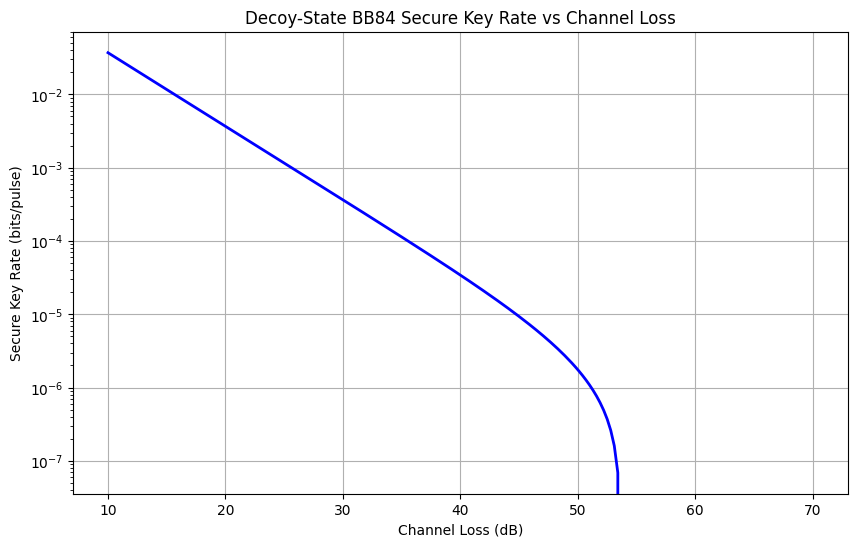

In [27]:
plt.figure(figsize=(10, 6))
plt.semilogy(loss_dB, key_rates, 'b-', linewidth=2)
plt.xlabel('Channel Loss (dB)')
plt.ylabel('Secure Key Rate (bits/pulse)')
plt.title('Decoy-State BB84 Secure Key Rate vs Channel Loss')
plt.grid(True)
plt.show()

The above graph shows us the following information-

1. At $10$dB loss, the secure key rate is the most optimal. This means that at this level, we have approximately $0.03$ bits per pulse which means for every $100$ bits, $3$ of them turn into secure key. At $100$MHz, thats roughly about $3,000,000$ secure key bits per second. Compared to the fact that for encrypting a phone call we require $\approx 64,000$ bits per second.
2. The loss that we calculated for our channel is around $\approx 15.8$dB, which according this plot gives us a rate of around $0.007$ bits per pulse, which for a transmission frequency of around $100$MHz gives us $700,000$ secure bits per second, more than enough for practical encryption.
3. The key difference between the first money plot and this is the fact that, here we make use of the decoy state generation, which alongwith the QBER, facors in error-correction costs and the security proof tells us the number of secure key bits that can be generated by the system. When the plot hits zero (which in this case is roughly at around $53$dB), the system does not generate anything.

# Layer 4- Orbit Pass Integrattion

Now we actually begin simulating the passing of a LEO satellite above a recieving station. This layer includes the following-

1. **Model a LEO satellite pass**- we assume that the satellite is moving around the Earth at a distance (height) of 500km from the surface. As it moves overhead, it forms an arc with the elevation angle changing at each point (rise, peaks, sets).
2.  **Convert Elevation Angle to Channel Loss**- computing the slant range from elevation angle at each moment and acquiring the instantaneous key rate by feeding it back through Layers 1-3 (including the loss parameters we assumed before).
3.  **Integrate over the entire pass**- summing up over all the instantaneous key rates for the entire pass duration to get the total secret bits per satellite contact
4.  **Money Plot 3**- secret bits per LEO pass versus maximum elevation angle at pass.

## The Physics-

When the LEO passes over a ground station, its elevation angle changes every time since it makes an arc overhead as it passes. The elevation angle changes at each moment- rising at first, reaching the maximum elevation angle and then decreasing as it flies by. If it is directly overhead, it makes a maximum elevation angle of $90^\circ$ but it can differ for different moments as it may not always fly directly overhead the station.

It is essential to have the following relationships defined-

1. For a circular orbit at a height of 500km, we can model the elevation angle per unit time using orbital geometry. The slant range i.e. the distance from the ground station to the satellite above is given as-
   $R_{slant}=-R_{earth}*sin(\theta)+\sqrt{(R_{earth}*sin(\theta))^2+2*R_{earth}*h+h^2}$
2. We evaluate the elevation angle per unit time starting from a minimum elevation angle (say $10^\circ$), all the way to the peak and then decreasing back to the starting minimum angle. We discretize the pass into small time steps and evaluate the instantaneous key rate at each time step.
3. The total key per pass is then computed. For each time step, we evaluate the instantaneous key rate (bits/pulse), multiply it with the pulse rate (e.g. at $100$MHz), multiply with the time step duration and then summing over all of these.

In [29]:
# function converting elevation angle to slant range

def slant_range(elevat_deg, h_km):
    R_earth=6371 #kms
    theta=np.radians(elevat_deg)
    L=-R_earth*np.sin(theta)+np.sqrt((R_earth*np.sin(theta))**2+2*R_earth*h_km+h_km**2)
    return L*1000 #converted to metres
dist=slant_range(10,500)
print("The slant range is", dist)

The slant range is 1694567.2211546793


In [37]:
# function that takes in the maximum elevation angle for a pass and generates the total secret keys during the pass

def key_per_pass(max_elev_deg, h_km=500, pulse=1e8):
    #parameters
    w_0=0.05
    wavelength=850e-9
    a=0.5
    T_zenith=0.8
    eta_optics=0.5
    eta_det=0.2
    Y0=1e-6
    e_d=0.02
    mu=0.5
    nu=0.1
    f=1.16
    min_elev=10 # minimum elevation angle at the start

    # sweep elevation from min_elev to max_elev to min_elev
    elevations_up=np.linspace(min_elev, max_elev_deg, 100)
    elevations_down=np.linspace(max_elev_deg, min_elev, 100)
    elevations=np.concatenate([elevations_up, elevations_down])

    # Time per step (approximate time duration for pass of LEO ~ 5 mins)
    total_time=300
    dt= total_time/len(elevations)

    total_bits=0

    for elev in elevations:
        # Get in slant range
        L=slant_range(elev, h_km)

        # Compute channel transmittance using existing functions
        eta_geo = geo_eff(w_0, L, wavelength, a)
        T_atm = atm_transm(T_zenith, np.radians(elev))
        eta_total = eta_geo * T_atm * eta_optics

        # Compute key rates
        Q1, e1, Q_mu, E_mu = decoy_estimation(mu, nu, eta_total, Y0, e_d)
        rate = secure_key_rate(Q1, e1, Q_mu, E_mu, f)

        # Accumulate bits
        total_bits += rate*pulse*dt
    return total_bits

keys= key_per_pass(30, 500, 1e8)
print("The total number of keys:", keys)

The total number of keys: 36356612.483309865


In [39]:
keys= key_per_pass(90, 500, 1e8)
print("The total number of keys:", keys)

The total number of keys: 163035992.08767906


As one can observe from above, the total number of secret bits generate depends on the maximum elevation angle. For a maximum elevation angle of $30^\circ$, we have roughly 36 million secret bits generated in compared to around 163 million secret bits for a maximum elevation angle of $90^\circ$. 

Now we generate the Money Plot wherein we sweep over the entire range of minimum and maximum elevation angle and print the total secret bits generated per pass.

## The Third Money Plot- Total secret bits per pass for a range of elevation angles.

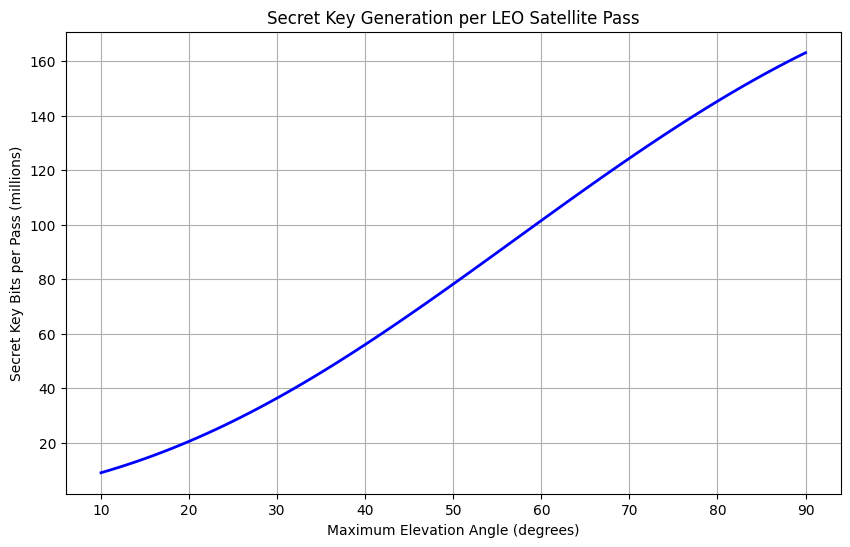

In [42]:
max_elevations=np.arange(10,91,1)
bits_per_pass=[]

for elev in max_elevations:
    bits=key_per_pass(elev)
    bits_per_pass.append(bits)

plt.figure(figsize=(10, 6))
plt.plot(max_elevations, [b / 1e6 for b in bits_per_pass], 'b-', linewidth=2)
plt.xlabel('Maximum Elevation Angle (degrees)')
plt.ylabel('Secret Key Bits per Pass (millions)')
plt.title('Secret Key Generation per LEO Satellite Pass')
plt.grid(True)
plt.show()